In [1]:
import pandas as pd
import numpy as np

## 1. Environment Setup and Data Loading

In this section, we import the foundational data science libraries and load the historical hotel booking dataset. To ensure environment reproducibility, the dataset is loaded using relative paths.

In [43]:
import pandas as pd
import numpy as np

ruta_datos = '../hotel_booking_demand_data_set/hotel_bookings.csv'

df = pd.read_csv(ruta_datos)

print(f"Success: {df.shape}")

Success: (119390, 32)


## 2. Data Cleaning and Feature Engineering

Marketing Mix Models require aggregated time-series data. Here, we filter out canceled bookings, compute the total length of stay, and calculate the gross revenue per transaction using the Average Daily Rate (ADR). The data is then resampled into weekly cohorts to stabilize the variance for the regression model.

In [44]:
import numpy as np

df_clean = df[df['is_canceled'] == 0].copy()

df_clean['total_nights'] = df_clean['stays_in_weekend_nights'] + df_clean['stays_in_week_nights']

df_clean['total_nights'] = df_clean['total_nights'].replace(0, 1)
df_clean['revenue'] = df_clean['total_nights'] * df_clean['adr']

month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}
df_clean['month_num'] = df_clean['arrival_date_month'].map(month_map)

df_clean['arrival_date'] = pd.to_datetime(
    df_clean['arrival_date_year'].astype(str) + '-' +
    df_clean['month_num'].astype(str) + '-' +
    df_clean['arrival_date_day_of_month'].astype(str)
)


weekly_hotel_data = df_clean.resample('W-MON', on='arrival_date').agg(
    total_bookings=('is_canceled', 'count'),
    total_room_nights=('total_nights', 'sum'),
    total_revenue=('revenue', 'sum'),
    avg_adr=('adr', 'mean')
).reset_index()


weekly_hotel_data.head()

,arrival_date,total_bookings,total_room_nights,total_revenue,avg_adr
0,2015-07-06,299,1387,135368.95,97.369699
1,2015-07-13,282,1286,148106.07,108.385390
2,2015-07-20,391,1635,203487.20,115.190153
3,2015-07-27,391,1519,189969.67,110.004834
4,2015-08-03,330,1682,224302.05,126.298394


## 3. Time Series Validation

A brief sanity check on the aggregated weekly data to verify the timeline boundaries, the number of weeks processed, and the overall cumulative revenue.

In [45]:
print(f"Total de semanas procesadas: {len(weekly_hotel_data)}")
print(f"Rango de fechas: de {weekly_hotel_data['arrival_date'].min().date()} a {weekly_hotel_data['arrival_date'].max().date()}")
print(f"Revenue total acumulado: ${weekly_hotel_data['total_revenue'].sum():,.2f}")

Total de semanas procesadas: 114
Rango de fechas: de 2015-07-06 a 2017-09-04
Revenue total acumulado: $25,996,260.41


## 4. Paid Media Spend Simulation

Since the original public dataset lacks marketing expenditure data, we simulate weekly ad spend across three primary channels: Google Ads (high-intent search), Meta Ads (prospecting and retargeting), and TikTok Ads (top-of-funnel discovery). Statistical noise is injected to prevent perfect multicollinearity while maintaining realistic seasonal correlations with the revenue.

In [48]:
import numpy as np


np.random.seed(42)


weekly_hotel_data['spend_google_ads'] = (weekly_hotel_data['total_revenue'] * 0.06) + np.random.normal(1500, 300, len(weekly_hotel_data))


weekly_hotel_data['spend_meta_ads'] = (weekly_hotel_data['total_revenue'] * 0.035) + np.random.normal(800, 200, len(weekly_hotel_data))


weekly_hotel_data['spend_tiktok_ads'] = (weekly_hotel_data['total_revenue'] * 0.015) + np.random.normal(300, 100, len(weekly_hotel_data))


columnas_gasto = ['spend_google_ads', 'spend_meta_ads', 'spend_tiktok_ads']
for col in columnas_gasto:
    weekly_hotel_data[col] = weekly_hotel_data[col].clip(lower=0)

print(weekly_hotel_data[['arrival_date', 'total_revenue'] + columnas_gasto].head())

  arrival_date  total_revenue  spend_google_ads  spend_meta_ads  \
0   2015-07-06      135368.95       9771.151246     5499.441057   
1   2015-07-13      148106.07      10344.884910     6044.021918   
2   2015-07-20      203487.20      13903.538561     7915.109646   
3   2015-07-27      189969.67      13355.089157     7215.202842   
4   2015-08-03      224302.05      14887.876988     8879.136313   

   spend_tiktok_ads  
0       2259.003879  
1       2589.550825  
2       3279.271337  
3       3171.190909  
4       3669.087934  


## 5. Exploratory Data Analysis: Revenue vs. Investment

Visualizing the seasonal trends of the organic hotel demand juxtaposed against the simulated multi-channel advertising spend. This helps identify high-season peaks and media scaling patterns.

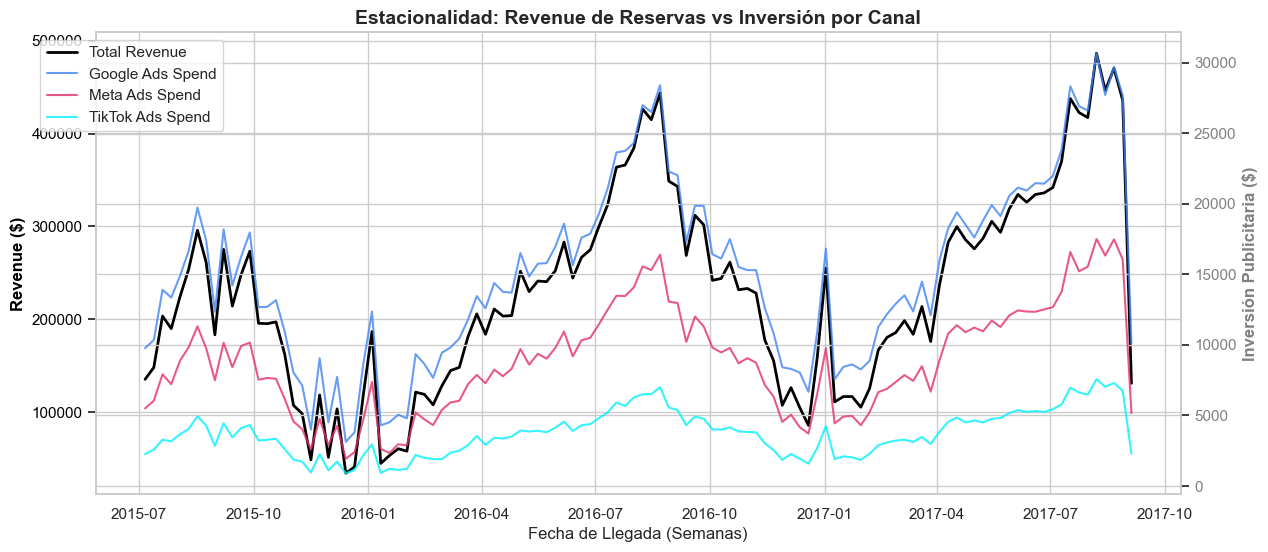

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(14, 6))


sns.lineplot(data=weekly_hotel_data, x='arrival_date', y='total_revenue', color='black', linewidth=2, label='Total Revenue', ax=ax1)
ax1.set_ylabel('Revenue ($)', color='black', fontweight='bold')
ax1.set_xlabel('Fecha de Llegada (Semanas)')
ax1.tick_params(axis='y', labelcolor='black')


ax2 = ax1.twinx()
sns.lineplot(data=weekly_hotel_data, x='arrival_date', y='spend_google_ads', color='#4285F4', alpha=0.8, label='Google Ads Spend', ax=ax2)
sns.lineplot(data=weekly_hotel_data, x='arrival_date', y='spend_meta_ads', color='#E1306C', alpha=0.8, label='Meta Ads Spend', ax=ax2)
sns.lineplot(data=weekly_hotel_data, x='arrival_date', y='spend_tiktok_ads', color='#00F2FE', alpha=0.8, label='TikTok Ads Spend', ax=ax2)

ax2.set_ylabel('Inversión Publicitaria ($)', color='gray', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='gray')

plt.title('Estacionalidad: Revenue de Reservas vs Inversión por Canal', fontsize=14, fontweight='bold')
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
ax1.get_legend().remove()
ax2.get_legend().remove()

plt.show()

## 6. Econometric Transformations: Adstock and Saturation

To model true consumer behavior, we apply two fundamental mathematical transformations to our raw media spend:
1. **Adstock (Advertising Memory):** Captures the delayed, residual impact of an ad impression over time using a decay rate ($\lambda$).
2. **Hill Function (Saturation):** Models the diminishing marginal returns of scaling ad budgets, identifying the threshold where audience saturation drastically increases the Cost Per Acquisition (CPA).

In [50]:
import numpy as np
import pandas as pd


def apply_adstock(spend_series, decay_rate):
    spend = np.array(spend_series)
    adstocked = np.zeros(len(spend))
    adstocked[0] = spend[0]
    for t in range(1, len(spend)):
        adstocked[t] = spend[t] + decay_rate * adstocked[t-1]
    return adstocked


def apply_hill_saturation(adstocked_array, alpha, gamma):
    return (adstocked_array ** alpha) / (adstocked_array ** alpha + gamma ** alpha)


weekly_hotel_data['adstock_google'] = apply_adstock(weekly_hotel_data['spend_google_ads'], decay_rate=0.3)
weekly_hotel_data['transf_google'] = apply_hill_saturation(weekly_hotel_data['adstock_google'], alpha=0.8, gamma=2000)


weekly_hotel_data['adstock_meta'] = apply_adstock(weekly_hotel_data['spend_meta_ads'], decay_rate=0.5)
weekly_hotel_data['transf_meta'] = apply_hill_saturation(weekly_hotel_data['adstock_meta'], alpha=1.2, gamma=1200)


weekly_hotel_data['adstock_tiktok'] = apply_adstock(weekly_hotel_data['spend_tiktok_ads'], decay_rate=0.7)
weekly_hotel_data['transf_tiktok'] = apply_hill_saturation(weekly_hotel_data['adstock_tiktok'], alpha=1.5, gamma=500)


print(weekly_hotel_data[['arrival_date', 'spend_meta_ads', 'adstock_meta', 'transf_meta']].head())

  arrival_date  spend_meta_ads  adstock_meta  transf_meta
0   2015-07-06     5499.441057   5499.441057     0.861379
1   2015-07-13     6044.021918   8793.742447     0.916066
2   2015-07-20     7915.109646  12311.980870     0.942345
3   2015-07-27     7215.202842  13371.193277     0.947496
4   2015-08-03     8879.136313  15564.732952     0.955859


## 7. Model Training & Coefficient Extraction

We train a Multiple Linear Regression model using the transformed media variables. This algorithm isolates the hotel's organic demand (**Baseline Revenue**) from the incremental sales driven by Paid Media, allowing us to extract the precise impact multiplier for each channel.

In [51]:
from sklearn.linear_model import LinearRegression

X = weekly_hotel_data[['transf_google', 'transf_meta', 'transf_tiktok']]
y = weekly_hotel_data['total_revenue']

mmm_model = LinearRegression()
mmm_model.fit(X, y)

baseline = mmm_model.intercept_
coef_google, coef_meta, coef_tiktok = mmm_model.coef_

print(f"Revenue Base (Reservas Orgánicas / Directas): ${baseline:,.2f} por semana")
print(f"Multiplicador (Coeficiente) Google Ads: {coef_google:,.2f}")
print(f"Multiplicador (Coeficiente) Meta Ads: {coef_meta:,.2f}")
print(f"Multiplicador (Coeficiente) TikTok Ads: {coef_tiktok:,.2f}")

Revenue Base (Reservas Orgánicas / Directas): $-2,171,769.49 por semana
Multiplicador (Coeficiente) Google Ads: 6,334,320.22
Multiplicador (Coeficiente) Meta Ads: -9,337,935.72
Multiplicador (Coeficiente) TikTok Ads: 5,930,923.96


## 8. Historical Incremental ROAS Evaluation

By multiplying the fitted coefficients by the transformed spend, we calculate the exact revenue contribution per channel. Dividing this by the actual spend yields the Historical Incremental Return on Ad Spend (ROAS), establishing a benchmark for media efficiency.

In [54]:
weekly_hotel_data['contrib_google'] = coef_google * weekly_hotel_data['transf_google']
weekly_hotel_data['contrib_meta'] = coef_meta * weekly_hotel_data['transf_meta']
weekly_hotel_data['contrib_tiktok'] = coef_tiktok * weekly_hotel_data['transf_tiktok']

roas_google = weekly_hotel_data['contrib_google'].sum() / weekly_hotel_data['spend_google_ads'].sum()
roas_meta = weekly_hotel_data['contrib_meta'].sum() / weekly_hotel_data['spend_meta_ads'].sum()
roas_tiktok = weekly_hotel_data['contrib_tiktok'].sum() / weekly_hotel_data['spend_tiktok_ads'].sum()

print("\n--- INCREMENTAL ROAS ---")
print(f"Google Ads ROAS: {roas_google:.2f}x")
print(f"Meta Ads ROAS:   {roas_meta:.2f}x")
print(f"TikTok Ads ROAS: {roas_tiktok:.2f}x")


--- INCREMENTAL ROAS ---
Google Ads ROAS: 357.49x
Meta Ads ROAS:   -1008.85x
TikTok Ads ROAS: 1572.81x


## 9. Budget Optimization Scenarios

To translate the econometric model into actionable business intelligence, we simulate three strategic budget allocations for the hotel directors:
* **Conservative:** Protects net margins by minimizing CPA, ideal for low-demand periods.
* **Optimal (Recommended):** Pushes investment to the exact point where marginal CPA equals marginal profit, maximizing net revenue.
* **Aggressive:** Focuses on market share capture during peak seasons, accepting margin compression for maximum volume.

In [55]:
import pandas as pd

gasto_promedio_google = weekly_hotel_data['spend_google_ads'].mean()
gasto_promedio_meta = weekly_hotel_data['spend_meta_ads'].mean()
gasto_promedio_tiktok = weekly_hotel_data['spend_tiktok_ads'].mean()

escenarios = {
    'Conservador': {'google': 0.8, 'meta': 0.7, 'tiktok': 0.5},
    'Óptimo (Recomendado)': {'google': 1.1, 'meta': 1.2, 'tiktok': 1.0},
    'Agresivo (Cuota de Mercado)': {'google': 1.4, 'meta': 1.5, 'tiktok': 1.5}
}

resultados = []

for nombre, mults in escenarios.items():
 
    spend_g = gasto_promedio_google * mults['google']
    spend_m = gasto_promedio_meta * mults['meta']
    spend_t = gasto_promedio_tiktok * mults['tiktok']
    
    
    sat_g = apply_hill_saturation(spend_g, alpha=0.8, gamma=2000)
    sat_m = apply_hill_saturation(spend_m, alpha=1.2, gamma=1200)
    sat_t = apply_hill_saturation(spend_t, alpha=1.5, gamma=500)
    
   
    rev_g = coef_google * sat_g
    rev_m = coef_meta * sat_m
    rev_t = coef_tiktok * sat_t
    
    
    revenue_total_proyectado = baseline + rev_g + rev_m + rev_t
    inversion_total = spend_g + spend_m + spend_t
    roas_incremental = (rev_g + rev_m + rev_t) / inversion_total
    
    resultados.append({
        'Escenario': nombre,
        'Inversión Semanal ($)': round(inversion_total, 2),
        'Revenue Proyectado ($)': round(revenue_total_proyectado, 2),
        'ROAS Incremental': round(roas_incremental, 2)
    })


df_proyecciones = pd.DataFrame(resultados)
print("\n--- PROYECCIÓN DE ESCENARIOS DE NEGOCIO ---")
print(df_proyecciones.to_string(index=False))


df_proyecciones.to_csv('proyeccion_escenarios_mmm.csv', index=False)


--- PROYECCIÓN DE ESCENARIOS DE NEGOCIO ---
                  Escenario  Inversión Semanal ($)  Revenue Proyectado ($)  ROAS Incremental
                Conservador               20145.38               -30238.63            106.30
       Óptimo (Recomendado)               30953.50               136036.59             74.56
Agresivo (Cuota de Mercado)               40001.94               266684.38             60.96


## 10. Monthly Revenue Forecast (2027)

Applying a historical seasonality index to the selected investment scenarios, we project the monthly revenue for the upcoming fiscal year. The output is consolidated into an executive pivot table, ready to be exported to Business Intelligence dashboards (e.g., Looker Studio) for stakeholder review.

In [56]:
import pandas as pd
import numpy as np
import calendar


weekly_hotel_data['month'] = weekly_hotel_data['arrival_date'].dt.month
monthly_seasonality = weekly_hotel_data.groupby('month')['total_revenue'].sum()

seasonality_index = monthly_seasonality / monthly_seasonality.mean()


escenarios = {
    'Conservador': {'google': 0.8, 'meta': 0.7, 'tiktok': 0.5},
    'Óptimo': {'google': 1.1, 'meta': 1.2, 'tiktok': 1.0},
    'Agresivo': {'google': 1.4, 'meta': 1.5, 'tiktok': 1.5}
}

proyeccion_2027 = []


for mes in range(1, 13):
    indice_est = seasonality_index.get(mes, 1.0)
    semanas_por_mes = 4.33 
    
    for nombre, mults in escenarios.items():
        
        spend_g_mes = gasto_promedio_google * mults['google'] * semanas_por_mes * indice_est
        spend_m_mes = gasto_promedio_meta * mults['meta'] * semanas_por_mes * indice_est
        spend_t_mes = gasto_promedio_tiktok * mults['tiktok'] * semanas_por_mes * indice_est
        
    
        inv_mensual = spend_g_mes + spend_m_mes + spend_t_mes
        
        
        sat_g = apply_hill_saturation(np.array([spend_g_mes / semanas_por_mes]), alpha=0.8, gamma=2000)[0]
        sat_m = apply_hill_saturation(np.array([spend_m_mes / semanas_por_mes]), alpha=1.2, gamma=1200)[0]
        sat_t = apply_hill_saturation(np.array([spend_t_mes / semanas_por_mes]), alpha=1.5, gamma=500)[0]
        
       
        rev_inc_mes = ((coef_google * sat_g) + (coef_meta * sat_m) + (coef_tiktok * sat_t)) * semanas_por_mes
        
        
        rev_base_mes = (baseline * semanas_por_mes) * indice_est
        
      
        rev_total_mes = rev_base_mes + (rev_inc_mes * indice_est)
        
        proyeccion_2027.append({
            'Mes': calendar.month_name[mes],
            'Escenario': nombre,
            'Inversión ($)': round(inv_mensual, 2),
            'Revenue Proyectado ($)': round(rev_total_mes, 2)
        })

df_proyeccion = pd.DataFrame(proyeccion_2027)


tabla_revenue = df_proyeccion.pivot(index='Mes', columns='Escenario', values='Revenue Proyectado ($)')

tabla_revenue = tabla_revenue.reindex(calendar.month_name[1:13])

print("--- PROYECCIÓN DE REVENUE MENSUAL 2027 ---")
print(tabla_revenue.to_string())


df_proyeccion.to_csv('forecast_mensual_2027.csv', index=False)

--- PROYECCIÓN DE REVENUE MENSUAL 2027 ---
Escenario    Agresivo  Conservador      Óptimo
Mes                                           
January     165693.86  -1076097.94  -349882.73
February    273061.00   -987215.71  -249011.76
March       484708.44   -790308.82   -48523.01
April       898993.81   -383217.97   345417.10
May        1712058.51    413582.00  1121126.95
June       1395612.88    105337.97   818793.86
July       3234458.53   1873988.89  2583181.02
August     4534945.43   3109508.82  3840275.93
September  1361420.65     71887.14   786160.13
October     953157.12   -329699.50   396985.33
November    196989.01  -1051502.73  -320595.76
December    -21375.00  -1176603.18  -519469.39


In [16]:
import pandas as pd
import numpy as np


weekly_hotel_data['month'] = weekly_hotel_data['arrival_date'].dt.month


monthly_ly = weekly_hotel_data.groupby('month').agg(
    revenue_ly=('total_revenue', lambda x: x.mean() * 4.33),
    spend_google_ly=('spend_google_ads', lambda x: x.mean() * 4.33),
    spend_meta_ly=('spend_meta_ads', lambda x: x.mean() * 4.33),
    spend_tiktok_ly=('spend_tiktok_ads', lambda x: x.mean() * 4.33)
).reset_index()

monthly_ly['total_spend_ly'] = monthly_ly['spend_google_ly'] + monthly_ly['spend_meta_ly'] + monthly_ly['spend_tiktok_ly']


escenarios_crecimiento = {
    'Conservador': {'google': 1.05, 'meta': 1.0, 'tiktok': 0.8}, 
    'Óptimo (Recomendado)': {'google': 1.25, 'meta': 1.30, 'tiktok': 1.15}, 
    'Agresivo (Cuota de Mercado)': {'google': 1.60, 'meta': 1.80, 'tiktok': 2.0} 
}


def calcular_revenue_proyectado(spend_g, spend_m, spend_t):
   
    weekly_spend_g = spend_g / 4.33
    weekly_spend_m = spend_m / 4.33
    weekly_spend_t = spend_t / 4.33
    
    
    adstock_g_steady = weekly_spend_g / (1 - 0.3)
    adstock_m_steady = weekly_spend_m / (1 - 0.5)
    adstock_t_steady = weekly_spend_t / (1 - 0.7)
    
   
    sat_g = apply_hill_saturation(adstock_g_steady, alpha=0.8, gamma=2000)
    sat_m = apply_hill_saturation(adstock_m_steady, alpha=1.2, gamma=1200)
    sat_t = apply_hill_saturation(adstock_t_steady, alpha=1.5, gamma=500)
    
    
    rev_incremental_mensual = ((coef_google * sat_g) + (coef_meta * sat_m) + (coef_tiktok * sat_t)) * 4.33
    
    
    return (baseline * 4.33) + rev_incremental_mensual


proyecciones_mensuales = []

for nombre_escenario, mults in escenarios_crecimiento.items():
    df_proj = monthly_ly.copy()
    df_proj['Escenario'] = nombre_escenario
    
    
    df_proj['spend_google_ny'] = df_proj['spend_google_ly'] * mults['google']
    df_proj['spend_meta_ny'] = df_proj['spend_meta_ly'] * mults['meta']
    df_proj['spend_tiktok_ny'] = df_proj['spend_tiktok_ly'] * mults['tiktok']
    df_proj['total_spend_ny'] = df_proj['spend_google_ny'] + df_proj['spend_meta_ny'] + df_proj['spend_tiktok_ny']
    
    
    df_proj['revenue_ny'] = df_proj.apply(lambda row: calcular_revenue_proyectado(
        row['spend_google_ny'], row['spend_meta_ny'], row['spend_tiktok_ny']
    ), axis=1)
    
    
    df_proj['Crecimiento Inversión (%)'] = ((df_proj['total_spend_ny'] - df_proj['total_spend_ly']) / df_proj['total_spend_ly']) * 100
    df_proj['Crecimiento Revenue (%)'] = ((df_proj['revenue_ny'] - df_proj['revenue_ly']) / df_proj['revenue_ly']) * 100
    
 
    df_proj = df_proj[['Escenario', 'month', 'total_spend_ly', 'total_spend_ny', 'Crecimiento Inversión (%)', 
                       'revenue_ly', 'revenue_ny', 'Crecimiento Revenue (%)']]
    
    proyecciones_mensuales.append(df_proj)


df_forecast_final = pd.concat(proyecciones_mensuales, ignore_index=True)


df_forecast_final = df_forecast_final.round(2)

print("\n--- FORECAST MENSUAL GENERADO ---")
print("Exportando a 'forecast_mensual_escenarios.csv'...")
df_forecast_final.to_csv('forecast_mensual_escenarios.csv', index=False)


print(df_forecast_final[df_forecast_final['Escenario'] == 'Óptimo (Recomendado)'].head(6).to_string(index=False))


--- FORECAST MENSUAL GENERADO ---
Exportando a 'forecast_mensual_escenarios.csv'...
           Escenario  month  total_spend_ly  total_spend_ny  Crecimiento Inversión (%)  revenue_ly  revenue_ny  Crecimiento Revenue (%)
Óptimo (Recomendado)      1        66435.77        83211.44                      25.25   505537.51   581179.04                    14.96
Óptimo (Recomendado)      2        74338.23        93097.14                      25.23   574258.69   723128.29                    25.92
Óptimo (Recomendado)      3        97276.30       121844.50                      25.26   786304.34   961265.65                    22.25
Óptimo (Recomendado)      4       125113.74       156708.90                      25.25  1032284.50  1255240.59                    21.60
Óptimo (Recomendado)      5       139968.05       175320.76                      25.26  1167825.65  1353535.76                    15.90
Óptimo (Recomendado)      6       153555.82       192321.12                      25.25  1299256.21 

## 11. Executive Visualization: Investment & CPA Forecast

This section generates a business-ready visualization contrasting the historical ad spend with the proposed "Optimal" budget scenario. By overlaying the projected Cost of Sale (CPA %), we mathematically justify budget scaling to stakeholders by demonstrating cost efficiency and margin protection.

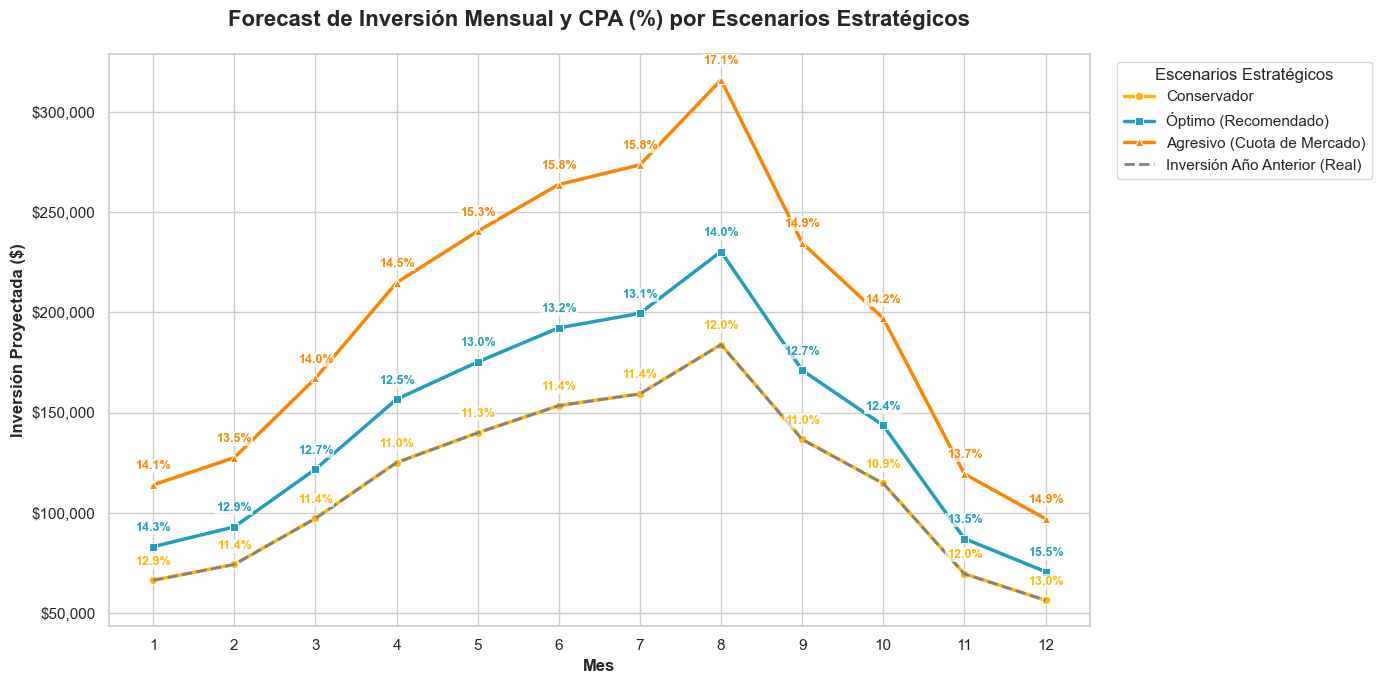

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker


sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 7))


colores_escenarios = {'Conservador': '#FFB703', 'Óptimo (Recomendado)': '#219EBC', 'Agresivo (Cuota de Mercado)': '#FB8500'}

sns.lineplot(
    data=df_forecast_final, 
    x='month', 
    y='total_spend_ny', 
    hue='Escenario', 
    style='Escenario',
    markers=['o', 's', '^'], 
    dashes=False,
    linewidth=2.5,
    palette=colores_escenarios,
    ax=ax
)


df_historico_inv = df_forecast_final[df_forecast_final['Escenario'] == 'Óptimo (Recomendado)']
sns.lineplot(
    data=df_historico_inv, 
    x='month', 
    y='total_spend_ly', 
    color='gray', 
    linestyle='--', 
    linewidth=2,
    label='Inversión Año Anterior (Real)',
    ax=ax
)


offset_y = df_forecast_final['total_spend_ny'].max() * 0.02

for escenario in df_forecast_final['Escenario'].unique():
    df_esc = df_forecast_final[df_forecast_final['Escenario'] == escenario]
    for _, row in df_esc.iterrows():
        cpa_pct = (row['total_spend_ny'] / row['revenue_ny']) * 100
        ax.text(
            row['month'], 
            row['total_spend_ny'] + offset_y,
            f'{cpa_pct:.1f}%', 
            color=colores_escenarios[escenario], 
            fontsize=9,
            fontweight='bold',
            ha='center',
            va='bottom',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.8) 
        )


ax.set_title('Forecast de Inversión Mensual y CPA (%) por Escenarios Estratégicos', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Mes', fontsize=12, fontweight='bold')
ax.set_ylabel('Inversión Proyectada ($)', fontsize=12, fontweight='bold')

ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'${int(x):,}'))


ax.legend(title='Escenarios Estratégicos', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()


plt.savefig('grafico_inversion_cpa_lineas.png', dpi=300, bbox_inches='tight')

plt.show()

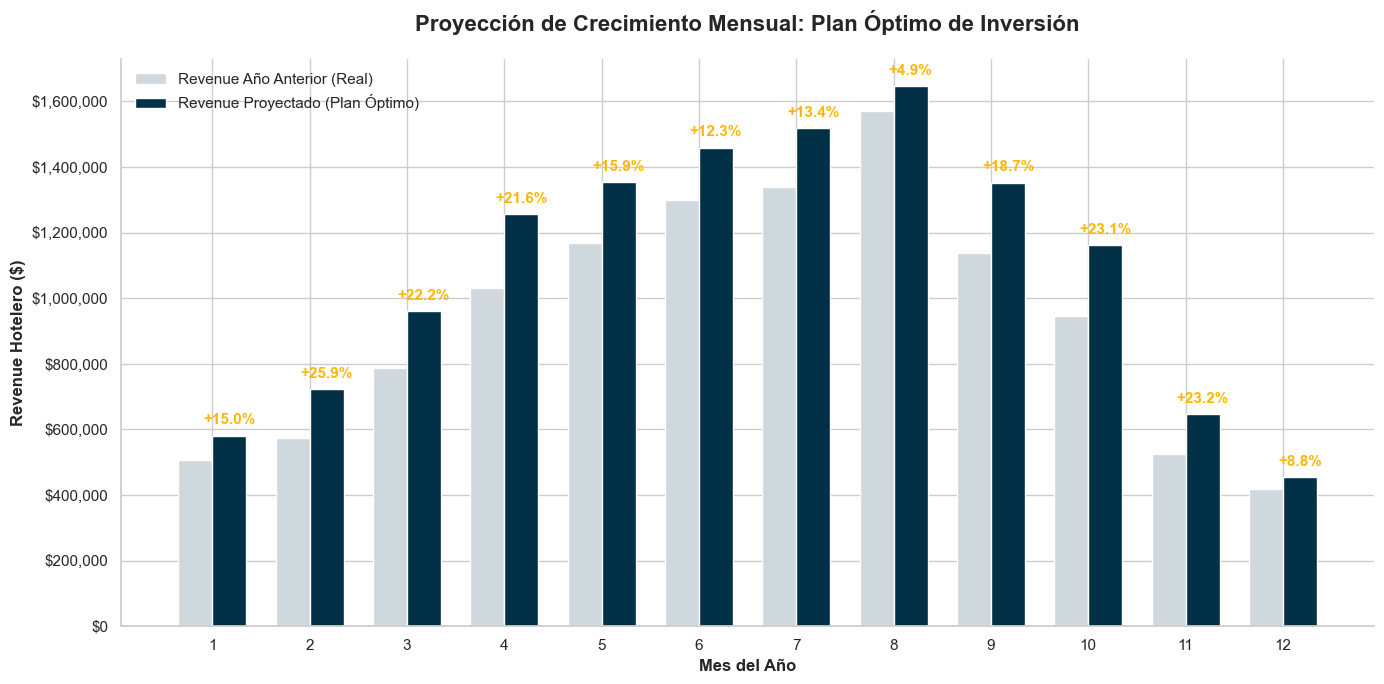

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker


df_optimo = df_forecast_final[df_forecast_final['Escenario'] == 'Óptimo (Recomendado)'].copy()

meses = df_optimo['month'].values
rev_ly = df_optimo['revenue_ly'].values
rev_ny = df_optimo['revenue_ny'].values
crecimiento_pct = df_optimo['Crecimiento Revenue (%)'].values


fig, ax = plt.subplots(figsize=(14, 7))
bar_width = 0.35
x = np.arange(len(meses))


bars1 = ax.bar(x - bar_width/2, rev_ly, bar_width, label='Revenue Año Anterior (Real)', color='#CFD8DC')
bars2 = ax.bar(x + bar_width/2, rev_ny, bar_width, label='Revenue Proyectado (Plan Óptimo)', color='#023047')


for i in range(len(x)):
    ax.text(
        x[i] + bar_width/2, 
        rev_ny[i] + (max(rev_ny) * 0.015),
        f'+{crecimiento_pct[i]:.1f}%', 
        ha='center', 
        va='bottom',
        fontsize=11, 
        fontweight='bold', 
        color='#FFB703' 
    )


ax.set_title('Proyección de Crecimiento Mensual: Plan Óptimo de Inversión', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Mes del Año', fontsize=12, fontweight='bold')
ax.set_ylabel('Revenue Hotelero ($)', fontsize=12, fontweight='bold')


ax.set_xticks(x)
ax.set_xticklabels(meses)


ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f'${int(val):,}'))


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(loc='upper left', frameon=False, fontsize=11)
plt.tight_layout()


plt.savefig('grafico_crecimiento_optimo.png', dpi=300, bbox_inches='tight')

plt.show()

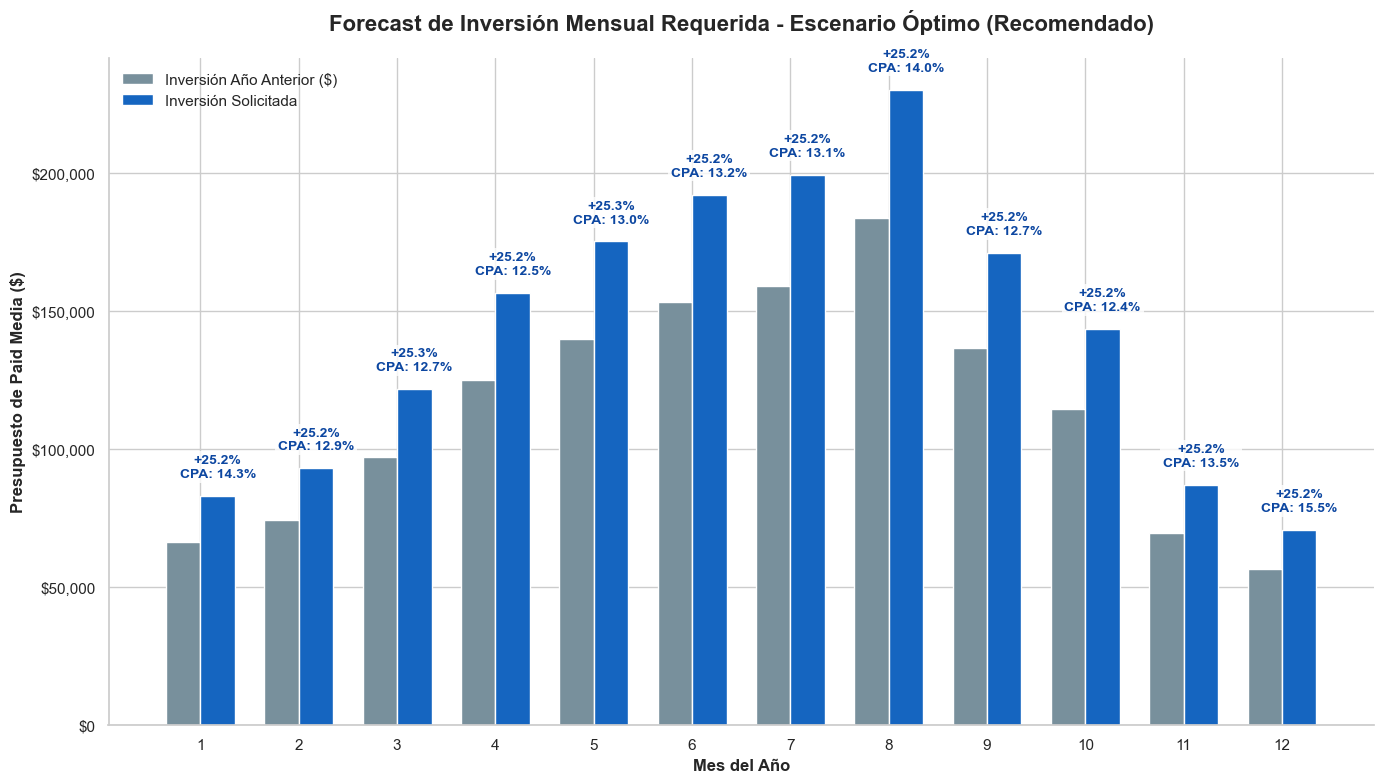

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker


df_optimo = df_forecast_final[df_forecast_final['Escenario'] == 'Óptimo (Recomendado)'].copy()

meses = df_optimo['month'].values
spend_ly = df_optimo['total_spend_ly'].values
spend_ny = df_optimo['total_spend_ny'].values
revenue_ny = df_optimo['revenue_ny'].values
crec_inversion_pct = df_optimo['Crecimiento Inversión (%)'].values


cpa_pct = (spend_ny / revenue_ny) * 100


fig, ax = plt.subplots(figsize=(14, 8))
bar_width = 0.35
x = np.arange(len(meses))


bars1 = ax.bar(x - bar_width/2, spend_ly, bar_width, label='Inversión Año Anterior ($)', color='#78909C') 
bars2 = ax.bar(x + bar_width/2, spend_ny, bar_width, label='Inversión Solicitada', color='#1565C0') 


for i in range(len(x)):
    etiqueta = f"+{crec_inversion_pct[i]:.1f}%\nCPA: {cpa_pct[i]:.1f}%"
    ax.text(
        x[i] + bar_width/2, 
        spend_ny[i] + (max(spend_ny) * 0.025), 
        etiqueta, 
        ha='center', 
        va='bottom',
        fontsize=10, 
        fontweight='bold', 
        color='#0D47A1', 
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2) 
    )


ax.set_title('Forecast de Inversión Mensual Requerida - Escenario Óptimo (Recomendado)', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Mes del Año', fontsize=12, fontweight='bold')
ax.set_ylabel('Presupuesto de Paid Media ($)', fontsize=12, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(meses)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f'${int(val):,}'))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(loc='upper left', frameon=False, fontsize=11)
plt.tight_layout()


plt.savefig('grafico_inversion_cpa_pct_optimo.png', dpi=300, bbox_inches='tight')

plt.show()

## 13. Tactical Media Mix Allocation

A stacked bar chart illustrating the precise monthly budget distribution across the media ecosystem (Google Ads, Meta Ads, and TikTok Ads). This provides a clear tactical roadmap for campaign execution and budget pacing throughout the fiscal year.

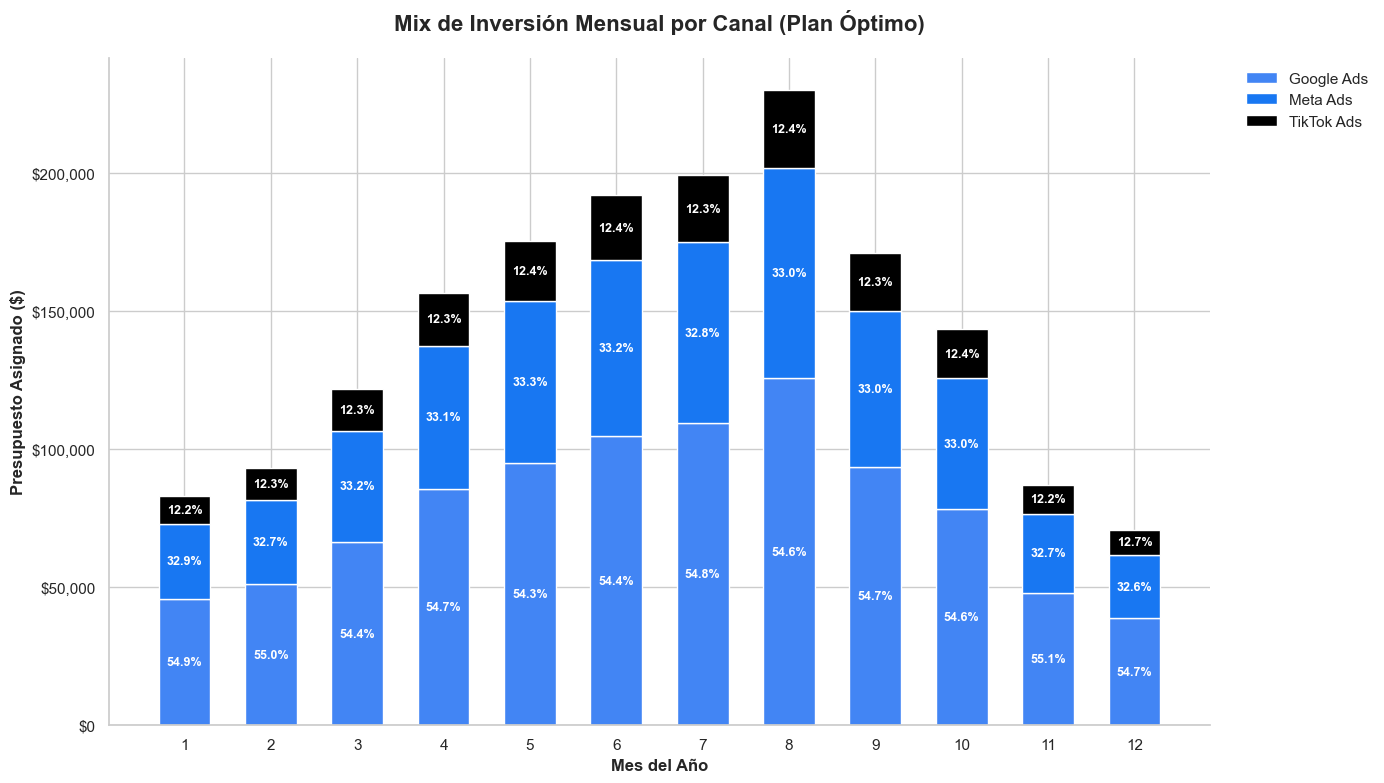

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker


df_optimo = df_forecast_final[df_forecast_final['Escenario'] == 'Óptimo (Recomendado)'].copy()

meses = df_optimo['month'].values
spend_google = df_optimo['spend_google_ny'].values
spend_meta = df_optimo['spend_meta_ny'].values
spend_tiktok = df_optimo['spend_tiktok_ny'].values
total_spend = df_optimo['total_spend_ny'].values


fig, ax = plt.subplots(figsize=(14, 8))
bar_width = 0.6


p1 = ax.bar(meses, spend_google, bar_width, label='Google Ads', color='#4285F4')

p2 = ax.bar(meses, spend_meta, bar_width, bottom=spend_google, label='Meta Ads', color='#1877F2')

p3 = ax.bar(meses, spend_tiktok, bar_width, bottom=spend_google + spend_meta, label='TikTok Ads', color='#000000')


for i in range(len(meses)):
 
    pct_g = (spend_google[i] / total_spend[i]) * 100
    if pct_g > 5: 
        ax.text(meses[i], spend_google[i] / 2, f'{pct_g:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    

    pct_m = (spend_meta[i] / total_spend[i]) * 100
    if pct_m > 5:
        ax.text(meses[i], spend_google[i] + (spend_meta[i] / 2), f'{pct_m:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    
    
    pct_t = (spend_tiktok[i] / total_spend[i]) * 100
    if pct_t > 5:
        ax.text(meses[i], spend_google[i] + spend_meta[i] + (spend_tiktok[i] / 2), f'{pct_t:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9)


ax.set_title('Mix de Inversión Mensual por Canal (Plan Óptimo)', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Mes del Año', fontsize=12, fontweight='bold')
ax.set_ylabel('Presupuesto Asignado ($)', fontsize=12, fontweight='bold')

ax.set_xticks(meses)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f'${int(val):,}'))


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, fontsize=11)
plt.tight_layout()

plt.show()

## 11. Statistical Model Validation (R² & MAPE)

To ensure the predictive model's reliability for financial planning, we evaluate its accuracy against historical data. We calculate the Coefficient of Determination ($R^2$) to verify how well the media spend explains revenue variance, and the Mean Absolute Percentage Error (MAPE) to quantify the average forecast deviation.

In [36]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_percentage_error


y_pred = mmm_model.predict(X)


r2 = r2_score(y, y_pred)


mape = mean_absolute_percentage_error(y, y_pred) * 100


print("--- VALIDACIÓN ESTADÍSTICA DEL MODELO ---")
print(f"R² (Coeficiente de Determinación): {r2 * 100:.2f}%")
print(f"MAPE (Margen de Error Promedio):   {mape:.2f}%")
print(f"Precisión Global del Forecast:     {100 - mape:.2f}%")

--- VALIDACIÓN ESTADÍSTICA DEL MODELO ---
R² (Coeficiente de Determinación): 89.92%
MAPE (Margen de Error Promedio):   19.92%
Precisión Global del Forecast:     80.08%
